# 10 — Binary Slime Mould Algorithm (BSMA) for feature selection

Continuous algorithm: *Li S. et al. (2020). Slime mould algorithm. Future Gener. Comput. Syst.*  
Binarised with the **Unified Binarization Framework (UBF)**: deterministic sign mapping, density-diverse initial population, fitness memoisation and elite bit-flip local search. RS = random-search control under the same framework. Protocol: see `00_data_and_protocol`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fsbench import experiment as ex, plots
pd.set_option("display.width", 200, "display.max_columns", 40)

In [2]:
METHOD = "SMA"
recs = ex.run_method(METHOD)
base = {m: ex.run_method(m) for m in ("ANOVA", "Chi2", "AllFeatures", "RS")}
df = ex.flatten(recs)
print(len(recs), "runs")

80 runs


## Performance on the test split (mean ± std over 10 runs)

In [3]:
plots.summary_table(df, by=("dataset", "classifier"))

,dataset,classifier,accuracy,precision_macro,recall_macro,f1_macro,auc_macro,n_selected,search_time_s
0,dermatology,ANN,0.9655 ± 0.0134,0.9672 ± 0.0153,0.9595 ± 0.0153,0.9611 ± 0.0155,0.9962 ± 0.0023,15.3 ± 2.3594,21.9691 ± 3.5025
1,dermatology,DT,0.9318 ± 0.0202,0.925 ± 0.0252,0.9165 ± 0.0306,0.9186 ± 0.0268,0.9541 ± 0.0174,15.3 ± 2.3594,21.9691 ± 3.5025
2,dermatology,KNN,0.9591 ± 0.015,0.9585 ± 0.0167,0.9523 ± 0.0188,0.9537 ± 0.0173,0.9891 ± 0.0073,15.3 ± 2.3594,21.9691 ± 3.5025
3,dermatology,RF,0.9564 ± 0.0094,0.9557 ± 0.009,0.9478 ± 0.0131,0.9496 ± 0.0118,0.9935 ± 0.0058,15.3 ± 2.3594,21.9691 ± 3.5025
4,dermatology,SVM,0.9645 ± 0.0151,0.9689 ± 0.0152,0.9562 ± 0.0183,0.9589 ± 0.0176,0.9961 ± 0.0027,15.3 ± 2.3594,21.9691 ± 3.5025
5,dermatology,XGB,0.9473 ± 0.017,0.9455 ± 0.0202,0.9393 ± 0.0182,0.9405 ± 0.0185,0.9903 ± 0.0052,15.3 ± 2.3594,21.9691 ± 3.5025
6,ionosphere,ANN,0.8896 ± 0.0134,0.8927 ± 0.0137,0.8658 ± 0.0189,0.876 ± 0.0162,0.9489 ± 0.0172,10.9 ± 3.3483,28.4452 ± 4.3658
7,ionosphere,DT,0.8745 ± 0.0285,0.8701 ± 0.0354,0.8563 ± 0.0253,0.8617 ± 0.0294,0.8563 ± 0.0253,10.9 ± 3.3483,28.4452 ± 4.3658
8,ionosphere,KNN,0.8679 ± 0.0172,0.8877 ± 0.0133,0.8274 ± 0.0242,0.8456 ± 0.0228,0.9078 ± 0.0252,10.9 ± 3.3483,28.4452 ± 4.3658
9,ionosphere,RF,0.9142 ± 0.0169,0.9134 ± 0.0169,0.8988 ± 0.0217,0.905 ± 0.0193,0.9755 ± 0.0111,10.9 ± 3.3483,28.4452 ± 4.3658


## Comparison with the classical filters (F1-macro, averaged over the six classifiers)

In [4]:
allb = pd.concat([df] + [ex.flatten(r) for r in base.values()])
pivot = allb.groupby(["dataset", "method"]).f1_macro.mean().unstack().round(4)
pivot

method,ANOVA,AllFeatures,Chi2,RS,SMA
dataset,,,,,
dermatology,0.9676,0.9568,0.9568,0.9552,0.9471
ionosphere,0.8734,0.8907,0.8734,0.8765,0.8798
musk1,0.8449,0.8634,0.8603,0.8553,0.8608
sonar,0.8293,0.8317,0.8188,0.7940,0.8070
spectf,0.5448,0.5448,0.5448,0.5471,0.5549
vehicle,0.6656,0.7311,0.6558,0.7273,0.7187
wdbc,0.9294,0.9442,0.9462,0.9291,0.9388
wine,0.9628,0.9524,0.9542,0.9530,0.9512


In [5]:
allb.groupby(["dataset", "method"])[["n_selected", "search_time_s"]].mean().unstack().round(2)

n_selected                                search_time_s                                
method           ANOVA AllFeatures   Chi2    RS   SMA         ANOVA AllFeatures  Chi2     RS    SMA
dataset                                                                                            
dermatology       24.0        34.0   34.0  18.1  15.3          0.36         0.0  0.23  13.37  21.97
ionosphere         3.0        33.0    3.0   6.4  10.9          0.33         0.0  0.32  15.02  28.45
musk1             66.0       166.0  133.0  55.9  76.6          0.38         0.0  0.28  21.06  26.49
sonar             24.0        60.0   30.0  21.5  25.9          0.30         0.0  0.28  11.13  17.39
spectf            44.0        44.0   44.0  16.9  19.9          0.31         0.0  0.20  12.17  17.45
vehicle            9.0        18.0    7.0  10.1   9.1          0.46         0.0  0.49  28.40  41.37
wdbc              18.0        30.0   21.0   9.9  10.4          0.37         0.0  0.35  20.84  37.62
wine               9.0        13.0    8.0   5.8   5.8          0.18         0.0  0.19   7.11  14.56

## Convergence: best-so-far fitness per iteration
A flat tail means the search converged within the budget; a still-decreasing tail means more iterations could help.

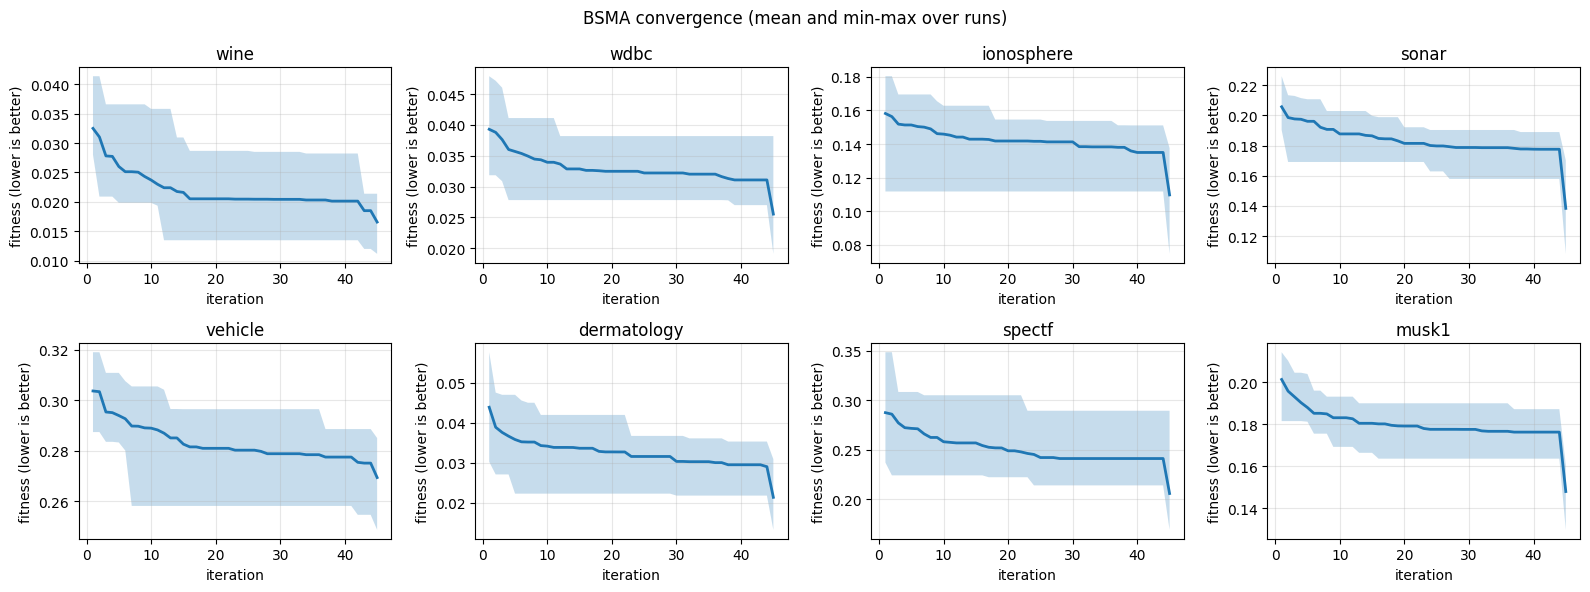

In [6]:
plots.convergence(recs, title="BSMA convergence (mean and min-max over runs)", name="convergence_SMA");

## Confusion matrices and ROC curves (run 0, KNN)

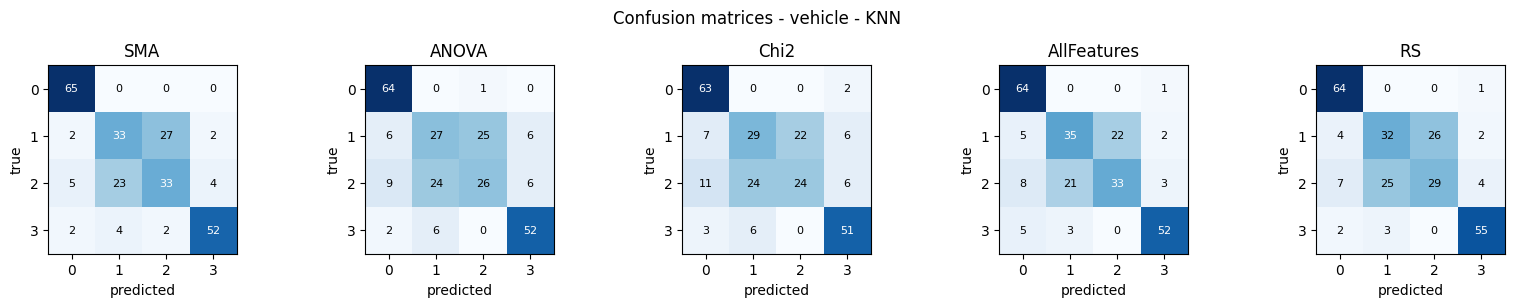

In [7]:
ds = "vehicle"
plots.confusion_matrices({METHOD: recs, **base}, ds, name=f"cm_{METHOD}_{ds}");

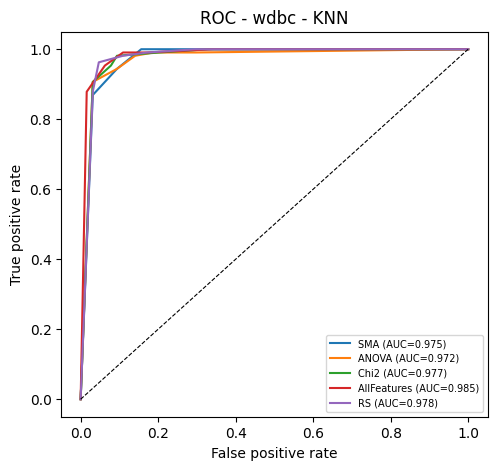

In [8]:
plots.roc_curves({METHOD: recs, **base}, "wdbc", name=f"roc_{METHOD}_wdbc");

## Computation
`n_classifier_fits` counts real classifier trainings; `cache_hits` are FEs served by the memo.

In [9]:
pd.DataFrame([{k: r[k] for k in ("dataset", "run", "n_selected", "time_s", "n_classifier_fits", "cache_hits")} for r in recs]).groupby("dataset").mean().round(2)

,run,n_selected,time_s,n_classifier_fits,cache_hits
dataset,,,,,
dermatology,4.5,15.3,21.97,956.4,43.6
ionosphere,4.5,10.9,28.45,956.7,43.3
musk1,4.5,76.6,26.49,995.6,4.4
sonar,4.5,25.9,17.39,968.8,31.2
spectf,4.5,19.9,17.45,964.6,35.4
vehicle,4.5,9.1,41.37,926.3,73.7
wdbc,4.5,10.4,37.62,955.8,44.2
wine,4.5,5.8,14.56,863.7,136.3
